# Telco Customer Churn — optimization, multi-objective, XAI and business
**Machine Learning, Task 6** · Felipe Quilumbango · App: https://telco-churn-v5dc.onrender.com/

**Business question:** which customers are most likely to leave, what drives that prediction, and which retention actions can be evaluated from the results?

| # | Section |
|---|---|
| 1 | Audit and preparation |
| 2 | Train/test split and pipeline |
| 3 | Model comparison |
| 4 | Hyperparameter optimization (Grid, Random, TPE) |
| 5 | Multi-objective optimization (NSGA-II) |
| 6 | Final evaluation on test |
| 7 | Explainable AI (SHAP, LIME, Feature Importance) |
| 8 | Export for Streamlit |
| 9 | Conclusions |

Each section ends with a **Findings** cell.

## Reglas metodológicas
- Mantenga **test aislado** hasta la evaluación final.
- Use `ColumnTransformer` y `Pipeline`.
- Compare al menos dos modelos con el mismo protocolo.
- No seleccione un modelo solo por Accuracy.
- La importancia predictiva de una variable **no demuestra causalidad**.
- La propuesta de negocio debe estar respaldada por sus resultados.


In [1]:
%pip install -q optuna lime shap

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score)

RANDOM_STATE = 42


In [3]:
import os
RUTA_DATASET = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"     # copy in the repo
if not os.path.exists(RUTA_DATASET):                              # running in Colab: dataset lives in Drive
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_DATASET = '/content/drive/MyDrive/Archivos_ML/Telco/WA_Fn-UseC_-Telco-Customer-Churn.csv'

## 1. Auditoría y preparación

Cargue `WA_Fn-UseC_-Telco-Customer-Churn.csv` y analice dimensiones, tipos, faltantes/inconsistencias, distribución de `Churn` y el problema de `TotalCharges`.

**TODO:** escriba 3–5 hallazgos que afecten decisiones posteriores.


In [4]:
df = pd.read_csv(RUTA_DATASET)

print(df.shape)       # (rows, columns)
df.info()             # column types and non-null counts
df.head()


(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Try converting to numeric; values that fail become NaN
tc_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Failed conversions:", tc_numeric.isna().sum())

# Inspect the problematic rows
df.loc[tc_numeric.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Failed conversions: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [6]:
for col in df.select_dtypes("object").columns:
    if col != "customerID":
        print(col, df[col].unique())

gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
TotalCharges ['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
Churn ['No' 'Yes']


In [7]:
# TODO 2 — Fix TotalCharges
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Sanity check: every missing value should belong to a tenure == 0 customer
missing = df["TotalCharges"].isna()
print("Missing:", missing.sum())
print("Tenure values of missing rows:", df.loc[missing, "tenure"].unique())

# Row-level rule: no tenure -> nothing accumulated yet
df.loc[missing & (df["tenure"] == 0), "TotalCharges"] = 0

print("Missing after fix:", df["TotalCharges"].isna().sum())
print(df["TotalCharges"].dtype)

Missing: 11
Tenure values of missing rows: [0]
Missing after fix: 0
float64


In [8]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [9]:
# Merge redundant categories into "No"
# (InternetService and PhoneService already keep that information)
internet_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]
df[internet_cols] = df[internet_cols].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# Verify
for col in internet_cols + ["MultipleLines"]:
    print(col, df[col].unique())

OnlineSecurity ['No' 'Yes']
OnlineBackup ['Yes' 'No']
DeviceProtection ['No' 'Yes']
TechSupport ['No' 'Yes']
StreamingTV ['No' 'Yes']
StreamingMovies ['No' 'Yes']
MultipleLines ['No' 'Yes']


In [10]:
df[(df['InternetService'] != 'No') & (df['OnlineSecurity'] == 'No') ]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7033,9767-FFLEM,Male,0,No,No,38,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Credit card (automatic),69.50,2625.25,No
7035,8456-QDAVC,Male,0,No,No,19,Yes,No,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Bank transfer (automatic),78.70,1495.10,No
7036,7750-EYXWZ,Female,0,No,No,12,No,No,DSL,No,...,Yes,Yes,Yes,Yes,One year,No,Electronic check,60.65,743.30,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No


In [11]:
raw = pd.read_csv(RUTA_DATASET)
pd.crosstab(raw["InternetService"], raw["OnlineSecurity"])

OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,1241,0,1180
Fiber optic,2257,0,839
No,0,1526,0


### Findings

1. **`TotalCharges` was stored as text.** 11 customers had a blank value instead of a number, so pandas read the column as `object` and `isnull()` reported 0 missing values. All 11 have `tenure = 0`: they are new customers who have not paid anything yet. I filled them with 0 because that is the true value, not an estimate. I did not drop these rows because new customers will keep arriving when the model is used in practice.

2. **Filling with 0 does not cause data leakage.** The rule only uses information from the same row (`tenure = 0`), not from any other customer, so it is safe to apply before the split. Filling with the median of the whole dataset would take information from other customers, including those in the test set. The training would have already seen information from the test data, and the test result would be too optimistic.

3. **`Churn` is imbalanced: 73.5% "No" and 26.5% "Yes".** Accuracy can be misleading because the majority class inflates it: a model that always predicts "No" would get 73.5% accuracy while detecting no customers who leave. Models must not be selected by Accuracy alone.

4. **"No internet service" and "No phone service" are redundant categories, so I merged them into "No".** "No internet service" appears in the 6 online-service columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) and "No phone service" in `MultipleLines`. No information is lost: a customer with internet who did not buy security has `InternetService` = DSL or Fiber optic and `OnlineSecurity = "No"`, while a customer without internet has "No" in both, so `InternetService` already tells the two cases apart. Without the merge, One-Hot Encoding would create `OnlineSecurity_No internet service`, which is 1 in exactly the 1526 rows where `InternetService = "No"` and 0 in every DSL or Fiber optic row (checked with `pd.crosstab`): a redundant column that adds nothing new.

## 2. Train/Test y pipeline
Separe objetivo/predictores. Analice `customerID`. Realice un split estratificado.

Construya un `ColumnTransformer` con tratamiento numérico y categórico y encapsúlelo en un `Pipeline`.

**Explique:** ¿cómo evita su procedimiento el data leakage?


In [12]:
# TODO 3 — X, y y split.
ids = df["customerID"]                       # kept aside: identifies who to contact (risk ranking, section 7)
X = df.drop(columns=["customerID", "Churn"])
y = (df["Churn"] == "Yes").astype(int)       # 1 = churn (positive class)

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, ids, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())


(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


### Findings — split

5. **`customerID` is not used as a predictor, but it is kept.** Every customer has a different ID, so it carries no pattern the model could learn. If it were one-hot encoded it would create 7043 columns, one per customer, greatly increasing the dimension the model learns from. It is kept aside (`ids_train`, `ids_test`) to know which customer each prediction belongs to, for example to contact the highest-risk customers.

In [13]:
# TODO 4 — numeric / categorical columns
# The dtype decides the treatment: numbers get scaled, text gets one-hot encoded.
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print(len(num_cols), num_cols)
print(len(cat_cols), cat_cols)
# TODO 5 — Preprocesamiento.
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# Nothing is fitted here: the pipeline will fit it on the training data only.

# TODO 6 — full pipeline: preprocessing + model travel together
lr_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
lr_pipe


4 ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
15 ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

### Findings — leakage

6. **The preprocessing lives inside the pipeline.** During cross-validation, in each fold the scaler computes its mean only with the rows that are not the validation fold; on the validation fold it only applies `transform`. If `X_train` were scaled before cross-validation, the mean would include the validation rows, so the model would be evaluated already knowing information about the data it is validated on. For the same reason `Churn` is not in `X`: it is the answer, and a new customer will not have it.

## 3. Modelado y comparación
Compare al menos dos modelos bajo los mismos folds. Puede usar Logistic Regression y Random Forest u otros modelos justificados.

Reporte Precision, Recall, F1 y ROC-AUC. Interprete especialmente los falsos negativos: clientes que realmente abandonan pero el modelo no detecta.


In [14]:
# TODO 7 — CV: 5 stratified folds, fixed seed -> every model sees the same splits
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# TODO 8 — same preprocessing, same folds, two models
rf_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
])

results = {}
for name, pipe in [("LogReg", lr_pipe), ("RandomForest", rf_pipe)]:
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: cv_res[f"test_{m}"].mean() for m in scoring}

pd.DataFrame(results).T.round(3)

,accuracy,precision,recall,f1,roc_auc
LogReg,0.802,0.654,0.543,0.593,0.846
RandomForest,0.786,0.627,0.479,0.543,0.823


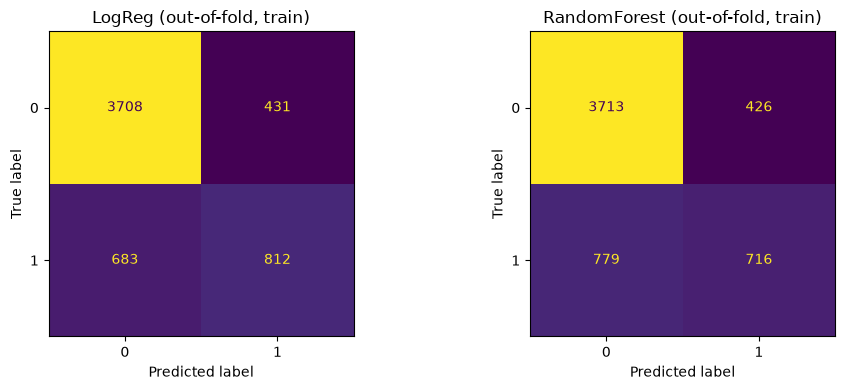

In [15]:
# Confusion matrices without touching test: out-of-fold predictions.
# Each training row is predicted by the fold model that did NOT train on it.
from sklearn.model_selection import cross_val_predict

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pipe) in zip(axes, [("LogReg", lr_pipe), ("RandomForest", rf_pipe)]):
    y_oof = cross_val_predict(pipe, X_train, y_train, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y_train, y_oof, ax=ax, colorbar=False)
    ax.set_title(f"{name} (out-of-fold, train)")
plt.tight_layout()
plt.show()

### Findings — candidate model (TODO 9)

7. **Recall is the metric that decides, and Logistic Regression is the candidate.** For a telco, a false negative costs more than a false positive: a false positive keeps paying the company, while a false negative is a direct loss of money. Logistic Regression has the highest recall in cross-validation (0.543 vs 0.479): out of every 100 customers who really leave, it detects 54, while Random Forest detects 48. The out-of-fold confusion matrices agree: Logistic Regression misses 683 churners (false negatives) and Random Forest misses 779. The ones it misses are customers the company loses.

8. **Accuracy is misleading here.** A model that predicts that no customer leaves would already get a high accuracy (0.735, the share of "No"), because the dataset is imbalanced, while it would almost never detect the customers who leave, which is what matters.

## 4. Optimización de hiperparámetros
Same pipeline, same 5 folds, same metric (F1) and the same budget (24 configurations) for Grid, Random and TPE. The main metric is fixed before looking at test.

In [16]:
# Experiment: what does class_weight="balanced" change? (same folds, same metrics)
cw_results = {}
for cw in [None, "balanced"]:
    pipe = Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=1000, class_weight=cw, random_state=RANDOM_STATE)),
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cw_results[str(cw)] = {m: res[f"test_{m}"].mean() for m in scoring}

pd.DataFrame(cw_results).T.round(3)

,accuracy,precision,recall,f1,roc_auc
None,0.802,0.654,0.543,0.593,0.846
balanced,0.749,0.517,0.803,0.629,0.846


In [17]:
# TODO 10 — Grid Search over the LogReg pipeline (same preprocess, same folds as Part 1)
import time

# Keys = "<pipeline step>__<parameter>": the grid reaches inside the "clf" step.
param_space = {
    "clf__C": np.logspace(-3, 2, 6),          # 0.001, 0.01, 0.1, 1, 10, 100
    "clf__penalty": ["l1", "l2"],
    "clf__class_weight": [None, "balanced"],
}

search_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(solver="liblinear", max_iter=1000, random_state=RANDOM_STATE)),
])

grid = GridSearchCV(search_pipe, param_space, scoring="f1", cv=cv, n_jobs=-1)

t0 = time.perf_counter()
grid.fit(X_train, y_train)          # test is never touched here
grid_time = time.perf_counter() - t0

# TODO 11 — best parameters and CV score
n_configs = len(grid.cv_results_["params"])
print(f"Configs: {n_configs} | fits: {n_configs * cv.get_n_splits()} | time: {grid_time:.1f} s")
print("Best params:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.3f}")

search_summary = {"Grid": {"configs": n_configs, "time_s": round(grid_time, 1),
                           "best_f1": round(grid.best_score_, 3), "best_params": grid.best_params_}}


Configs: 24 | fits: 120 | time: 2.9 s
Best params: {'clf__C': np.float64(0.01), 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'}
Best CV F1: 0.633


In [18]:
# Random Search — same pipeline, same folds, same metric, same budget (24 configs)
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

# C is now a distribution, not a list: any value in [0.001, 100] can be drawn (log scale).
param_dist = {
    "clf__C": loguniform(1e-3, 1e2),
    "clf__penalty": ["l1", "l2"],
    "clf__class_weight": [None, "balanced"],
}

rand = RandomizedSearchCV(search_pipe, param_dist, n_iter=n_configs, scoring="f1",
                          cv=cv, n_jobs=-1, random_state=RANDOM_STATE)

t0 = time.perf_counter()
rand.fit(X_train, y_train)
rand_time = time.perf_counter() - t0

print(f"Configs: {n_configs} | time: {rand_time:.1f} s")
print("Best params:", rand.best_params_)
print(f"Best CV F1: {rand.best_score_:.3f}")

search_summary["Random"] = {"configs": n_configs, "time_s": round(rand_time, 1),
                            "best_f1": round(rand.best_score_, 3), "best_params": rand.best_params_}


Configs: 24 | time: 0.7 s
Best params: {'clf__C': np.float64(0.01967432802530612), 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'}
Best CV F1: 0.633


In [19]:
# TPE (Optuna) — same space, same folds, same metric, same budget
# In Colab, if needed first: !pip install -q optuna
import optuna
from sklearn.model_selection import cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Each trial asks the sampler for a config; TPE uses the results of the previous trials to choose.
    params = {
        "clf__C": trial.suggest_float("C", 1e-3, 1e2, log=True),
        "clf__penalty": trial.suggest_categorical("penalty", ["l1", "l2"]),
        "clf__class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }
    pipe = search_pipe.set_params(**params)
    return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1).mean()

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
t0 = time.perf_counter()
study.optimize(objective, n_trials=n_configs)
tpe_time = time.perf_counter() - t0

print(f"Configs: {n_configs} | time: {tpe_time:.1f} s")
print("Best params:", study.best_params)
print(f"Best CV F1: {study.best_value:.3f}")

search_summary["TPE"] = {"configs": n_configs, "time_s": round(tpe_time, 1),
                         "best_f1": round(study.best_value, 3), "best_params": study.best_params}
pd.DataFrame(search_summary).T


/home/felkim/.venvs/telco/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Configs: 24 | time: 1.7 s
Best params: {'C': 0.015311828549009162, 'penalty': 'l2', 'class_weight': 'balanced'}
Best CV F1: 0.634


,configs,time_s,best_f1,best_params
Grid,24,2.9,0.633,"{'clf__C': 0.01, 'clf__class_weight': 'balance..."
Random,24,0.7,0.633,"{'clf__C': 0.01967432802530612, 'clf__class_we..."
TPE,24,1.7,0.634,"{'C': 0.015311828549009162, 'penalty': 'l2', '..."


### Findings — hyperparameter search (TODO 10–11)

9. **Grid, Random and TPE reach the same model.** Same pipeline, same 5 folds, same metric (F1) and the same budget of 24 configurations. Best CV F1: Grid 0.633 (30.8 s), Random 0.633 (22.5 s), TPE 0.634 (27.7 s). A difference of 0.001 in an average over 5 folds is noise: with another fold seed the order could change, so the three methods tie.
10. **The winning zone is strong regularization with balanced classes:** `C` ≈ 0.01–0.02, `penalty="l2"`, `class_weight="balanced"`. A small `C` keeps the weights small, so the model depends little on a single feature or on a rare pattern of the training data. `balanced` raises F1 because recall gains more than precision loses.
11. **Why TPE shows no advantage here.** The space has only 3 hyperparameters and only one of them (`C`) is continuous. Random can already try values the grid skips (e.g. between 0.001 and 0.01), and every method finds the good zone within 24 trials. TPE's advantage should appear with more continuous hyperparameters.


## 5. Optimización multiobjetivo (NSGA-II)
Two objectives at the same time: maximize recall and maximize precision. Then one point of the Pareto front is chosen by business cost.

Trials: 60 | time: 7.6 s


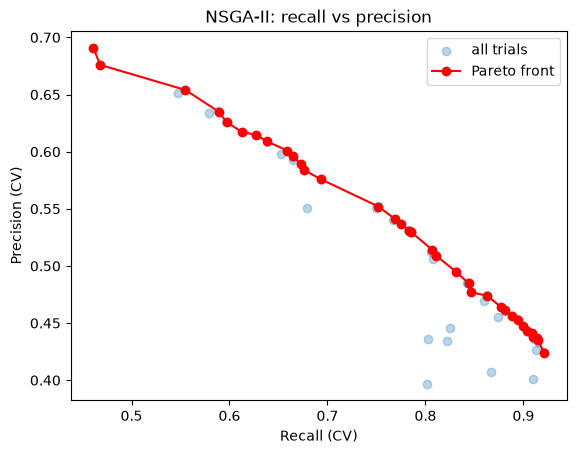

,recall,precision,churn_weight,C,penalty
33,0.461,0.691,1.025,0.004,l2
32,0.468,0.676,1.046,0.014,l1
11,0.555,0.654,1.028,11.948,l2
17,0.589,0.635,1.157,1.521,l2
25,0.597,0.626,1.204,0.900,l1
8,0.613,0.617,1.442,0.010,l2
5,0.627,0.615,1.325,55.517,l1
10,0.638,0.609,1.373,85.987,l1
34,0.659,0.601,1.451,1.451,l1
20,0.665,0.596,1.599,0.049,l1


In [20]:
# Multi-objective search (NSGA-II): maximize recall AND precision at the same time
# Same LogReg pipeline and folds. The weight of the churn class is now continuous (1 = no extra weight,
# ~2.8 = what "balanced" gives here), so the search can trade recall for precision gradually.
from sklearn.model_selection import cross_validate

def mo_objective(trial):
    w = trial.suggest_float("churn_weight", 1.0, 6.0)
    params = {
        "clf__C": trial.suggest_float("C", 1e-3, 1e2, log=True),
        "clf__penalty": trial.suggest_categorical("penalty", ["l1", "l2"]),
        "clf__class_weight": {0: 1.0, 1: w},
    }
    res = cross_validate(search_pipe.set_params(**params), X_train, y_train,
                         cv=cv, scoring=["recall", "precision"], n_jobs=-1)
    return res["test_recall"].mean(), res["test_precision"].mean()

mo_study = optuna.create_study(directions=["maximize", "maximize"],
                               sampler=optuna.samplers.NSGAIISampler(seed=RANDOM_STATE))
t0 = time.perf_counter()
mo_study.optimize(mo_objective, n_trials=60)
print(f"Trials: 60 | time: {time.perf_counter() - t0:.1f} s")

# Non-dominated trials = the Pareto front
front = mo_study.best_trials
front_df = pd.DataFrame([{"recall": t.values[0], "precision": t.values[1], **t.params} for t in front])
front_df = front_df.sort_values("recall").round(3)

all_vals = np.array([t.values for t in mo_study.trials])
plt.scatter(all_vals[:, 0], all_vals[:, 1], alpha=0.3, label="all trials")
plt.plot(front_df["recall"], front_df["precision"], "o-", color="red", label="Pareto front")
plt.xlabel("Recall (CV)"); plt.ylabel("Precision (CV)"); plt.legend(); plt.title("NSGA-II: recall vs precision")
plt.show()
front_df


In [21]:
# Business cost of each point of the Pareto front (hypothetical: 1 FN costs 12x one FP)
# The front only has recall/precision (CV means), so we rebuild the counts from them.
FN_COST, FP_COST = 12, 1
P = y_train.sum()                          # real churners in train = TP + FN
TP = front_df["recall"] * P                # recall = TP / P
front_df["FN"] = P - TP                    # churners the model missed
front_df["FP"] = TP / front_df["precision"] - TP   # precision = TP / (TP + FP)
front_df["cost"] = FN_COST * front_df["FN"] + FP_COST * front_df["FP"]
front_df.sort_values("cost").head().round({"FN": 1, "FP": 1, "cost": 1})


,recall,precision,churn_weight,C,penalty,FN,FP,cost
21,0.921,0.424,5.812,0.018,l1,118.1,1870.5,3287.8
18,0.915,0.435,5.648,10.980,l2,127.1,1776.7,3301.6
31,0.914,0.437,5.493,1.077,l1,128.6,1760.4,3303.3
12,0.909,0.441,5.316,1.308,l1,136.0,1722.6,3355.1
14,0.910,0.438,5.436,0.230,l2,134.5,1745.6,3360.2


### Findings — multi-objective search and business choice (step 3)

12. **Two objectives, recall and precision, because both errors cost money.** The buyer cares most about detecting the customers who leave (recall), but every false positive also costs: that customer receives the retention promotion without needing it. NSGA-II returns a whole Pareto front of non-dominated models instead of a single winner, from recall 0.461 / precision 0.691 to recall 0.921 / precision 0.424. Along the front only `churn_weight` rises in order with recall; `C` and `penalty` follow no pattern, so they matter little for this trade-off.
13. **Chosen point: row 31 (`churn_weight` ≈ 5.5, `C` ≈ 1.1, `l1`).** Hypothesis: one FN costs 12 times one FP (a lost customer is about a year of fees; a promotion is about one month of discount). Total cost = 12·FN + FP, with FN and FP rebuilt from recall, precision and the 1495 churners in train. The cheapest points are at the high-recall end: going from row 18 to row 21 saves 9 FN (108) and adds about 94 FP (94), so taking those FP costs less than keeping the FN. Rows 21, 18 and 31 cost 3288, 3302 and 3303: a difference of 14 in about 3300 is noise, so the three tie. Among them, row 31 gives about 110 fewer promotions than row 21 for practically the same cost, which matters for a company with a limited promotion budget.


## 6. Evaluación final
The chosen pipeline is evaluated **once** on test and compared with CV.

              precision    recall  f1-score   support

           0      0.949     0.580     0.720      1035
           1      0.440     0.914     0.594       374

    accuracy                          0.669      1409
   macro avg      0.695     0.747     0.657      1409
weighted avg      0.814     0.669     0.687      1409

ROC-AUC: 0.841


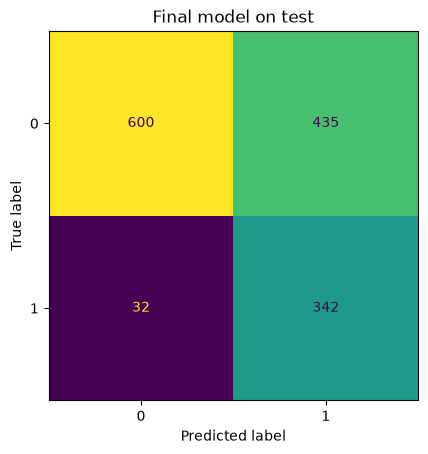

['model.joblib']

In [22]:
# TODO 12 — Final model: the chosen Pareto point (row 31), trained ONCE on all of train
# and evaluated ONCE on test. No decision before this cell looked at test.
import joblib
from sklearn.base import clone

best = front_df.loc[31]
final_pipe = clone(search_pipe).set_params(
    clf__C=best["C"],
    clf__penalty=best["penalty"],
    clf__class_weight={0: 1.0, 1: best["churn_weight"]},
)
final_pipe.fit(X_train, y_train)

y_pred = final_pipe.predict(X_test)
y_proba = final_pipe.predict_proba(X_test)[:, 1]      # column 1 = P(churn = 1)
print(classification_report(y_test, y_pred, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, colorbar=False)
plt.title("Final model on test")
plt.show()

joblib.dump(final_pipe, "model.joblib")   # Streamlit will load this file and never retrain


## 7. Explainable AI
SHAP (global and two customers), LIME on the same two customers, and the Feature Importance of the Random Forest. Explanations are associations learned by the model, not causes.

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


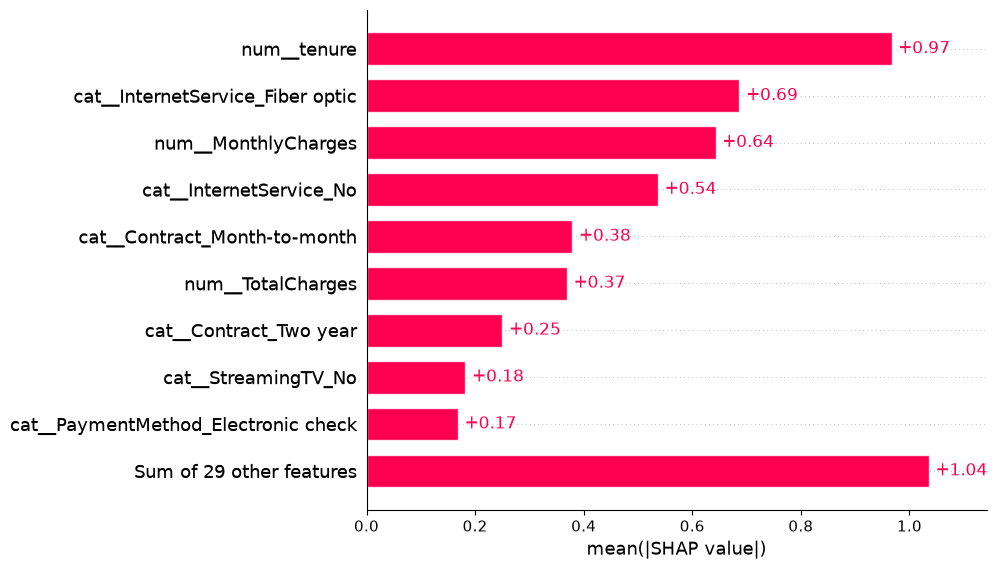

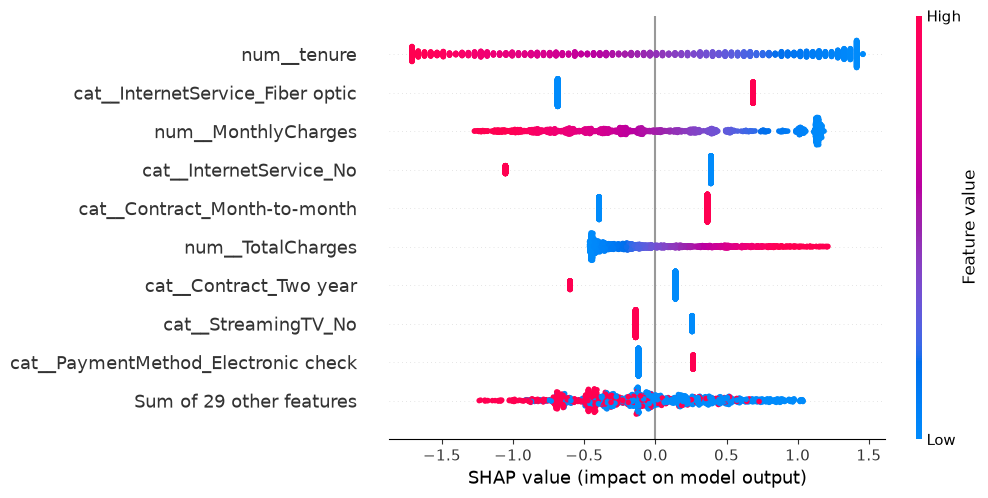

In [23]:
# Step 4 — SHAP (global). The LogReg never sees the raw columns: it sees the output of "prep"
# (scaled numbers + one-hot columns). So SHAP must explain it in that same space.
import shap

prep = final_pipe.named_steps["prep"]
clf = final_pipe.named_steps["clf"]
X_train_t = prep.transform(X_train)          # background: what an "average" customer looks like
X_test_t = prep.transform(X_test)            # customers we explain
feat_names = list(prep.get_feature_names_out())   # e.g. "cat__Contract_Month-to-month"

explainer = shap.LinearExplainer(clf, X_train_t)
sv = explainer(X_test_t)                     # one value per customer x feature (log-odds of churn)
sv.feature_names = feat_names

shap.plots.bar(sv, max_display=10)           # global: mean |SHAP| per feature
shap.plots.beeswarm(sv, max_display=10)      # global + direction: each dot is one customer


5178-LMXOP | P(churn) = 0.966 | real churn = 1


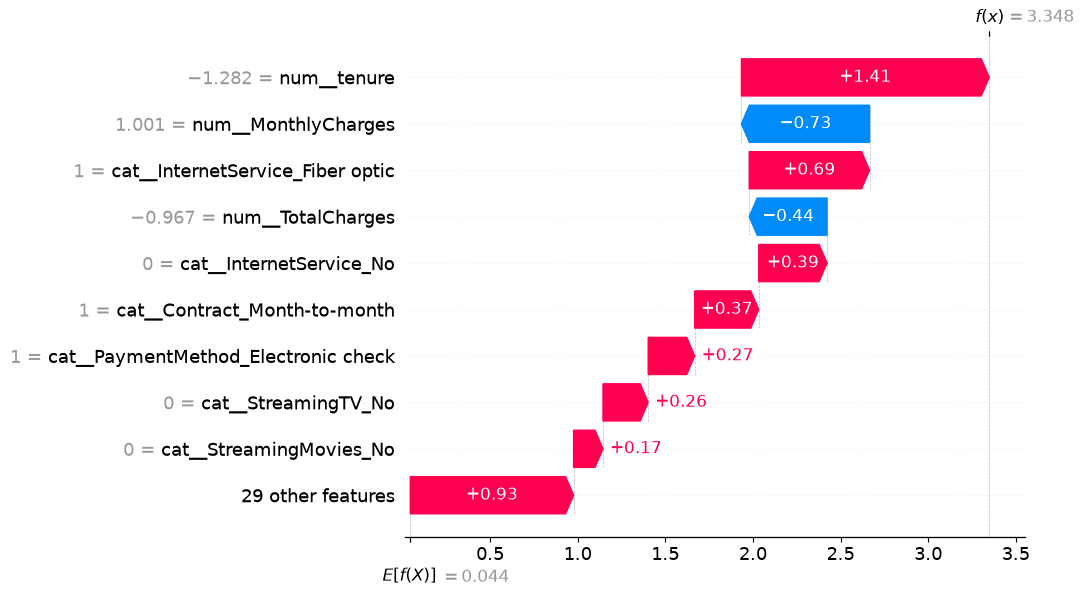

1166-PQLGG | P(churn) = 0.012 | real churn = 0


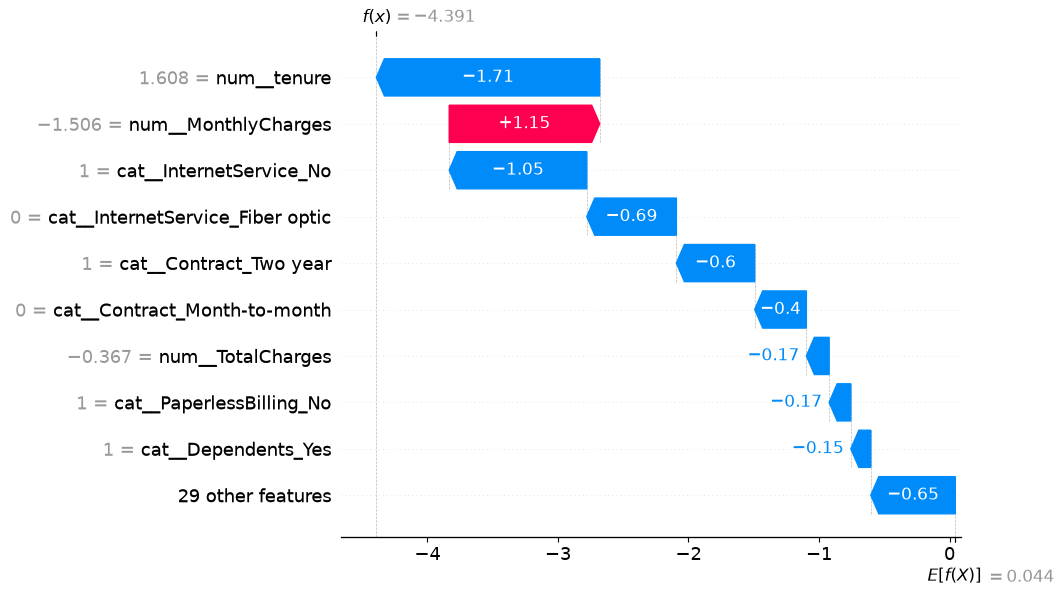

In [24]:
# Step 4 — SHAP local: two test customers explained one by one (the same two will go to LIME)
proba_test = pd.Series(y_proba, index=X_test.index)
i_high = proba_test.idxmax()                 # customer the model sees as most at risk
i_low = proba_test.idxmin()                  # customer the model sees as safest
chosen = [i_high, i_low]

for idx in chosen:
    pos = X_test.index.get_loc(idx)          # row number inside X_test_t / sv (they have no index)
    print(f"{ids_test.loc[idx]} | P(churn) = {proba_test[idx]:.3f} | real churn = {y_test.loc[idx]}")
    shap.plots.waterfall(sv[pos], max_display=10)   # starts at E[f(X)], ends at f(x) of this customer


5178-LMXOP | P(churn) = 0.966


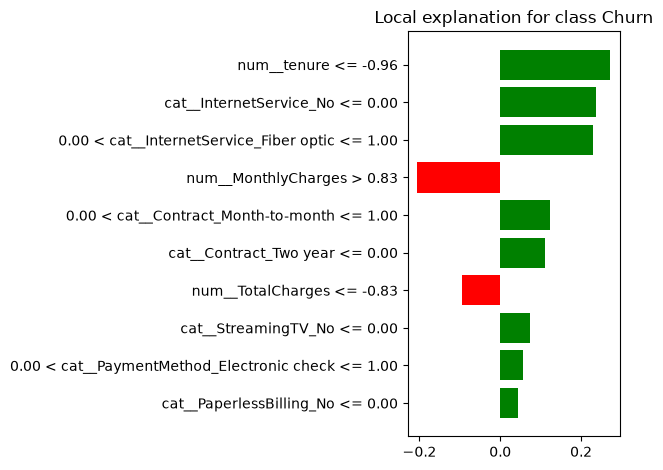

1166-PQLGG | P(churn) = 0.012


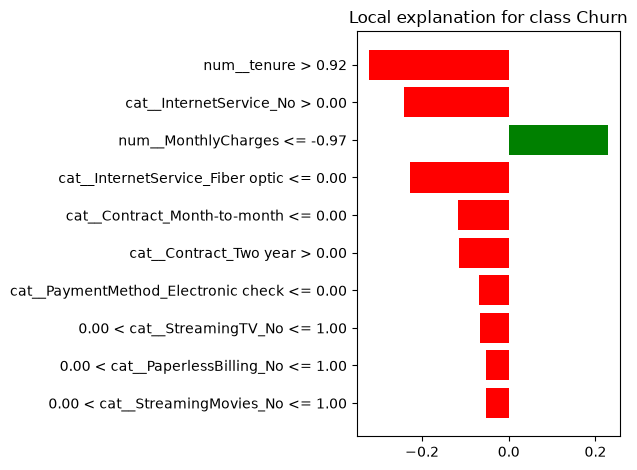

In [25]:
# Step 4 — LIME on the SAME two customers. For each one, LIME creates many slightly changed copies,
# asks the model P(churn) for each copy, and fits a small linear model around that customer.
# Its weights are the explanation. Same space as SHAP: the preprocessed columns.
# !pip install lime        # run once in Colab
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    np.asarray(X_train_t), feature_names=feat_names,
    class_names=["Stays", "Churn"], mode="classification", random_state=RANDOM_STATE)

for idx in chosen:
    pos = X_test.index.get_loc(idx)
    exp = lime_explainer.explain_instance(np.asarray(X_test_t)[pos], clf.predict_proba, num_features=10)
    print(f"{ids_test.loc[idx]} | P(churn) = {proba_test[idx]:.3f}")
    exp.as_pyplot_figure(label=1)          # label=1: green pushes toward Churn, red toward Stays
    plt.tight_layout()
    plt.show()


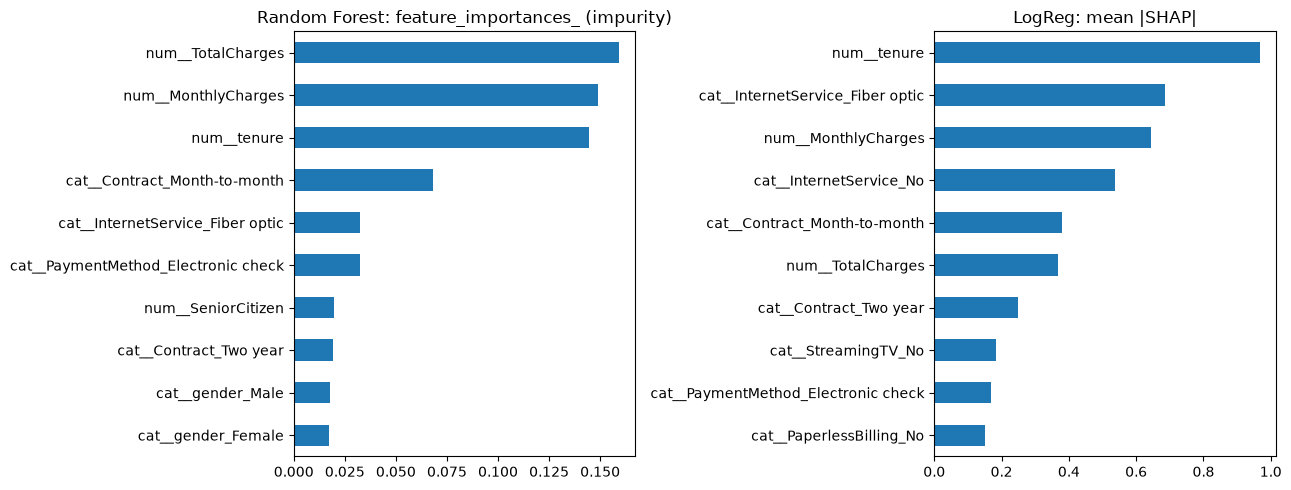

In [26]:
# Step 4 — Feature Importance of the Random Forest (the other model from Part 1), trained on train only,
# side by side with the global SHAP importance of the chosen LogReg.
rf_final = clone(rf_pipe).fit(X_train, y_train)
rf_fi = pd.Series(rf_final.named_steps["clf"].feature_importances_,
                  index=rf_final.named_steps["prep"].get_feature_names_out()).sort_values()
shap_imp = pd.Series(np.abs(sv.values).mean(axis=0), index=feat_names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rf_fi.tail(10).plot.barh(ax=axes[0], title="Random Forest: feature_importances_ (impurity)")
shap_imp.tail(10).plot.barh(ax=axes[1], title="LogReg: mean |SHAP|")
plt.tight_layout()
plt.show()


### Findings — final model and explainability (step 4)

14. **Final model on test.** Row 31 of the Pareto front was trained once on all of train and evaluated once on test: recall 0.914 and precision 0.440, the same as in cross-validation (0.914 / 0.437). A lower test score was expected, because the hyperparameters were chosen by looking at the CV folds, while test was never used for any decision. Here it held, so the recall we promise also holds for new customers.

15. **SHAP, global view.** The most relevant features are `tenure`, `InternetService_Fiber optic` and `MonthlyCharges`. The importance bar chart averages the absolute SHAP value: with the sign, a feature that pushes some customers toward "leaves" and others toward "stays" would see its average reduced and would look less important. In the beeswarm, customers with high tenure receive less churn risk from the model; a low tenure gives a positive SHAP value because its weight is negative.

16. **Two customers, SHAP and LIME.** The model sees the most at-risk customer as high risk first because they have very little time with the company, and also because they have fiber-optic internet (`InternetService_No = 0` only means that they do have internet, so it does not contradict `Fiber optic = 1`). LIME agrees: the same features appear and `tenure` is on top; only the order changes (`MonthlyCharges` is 2nd in SHAP and 4th in LIME, `TotalCharges` 4th and 7th). LIME's order can change with another seed because it relies on random copies of the customer; SHAP's does not, because it comes from the weights already defined in the model.

17. **Limitations, and the Random Forest Feature Importance.** LIME's copies are fictitious customers built by drawing each column separately, so it can invent impossible ones, for example a customer without internet but with fiber optic. The Random Forest Feature Importance tells which features matter but not in which direction they push: two features with the same bar cannot be told apart, because there is no label saying which one leads to churn. In the Random Forest, `tenure` is important but comes after `TotalCharges` and `MonthlyCharges`.

18. **Importance is not causality.** In SHAP, a high `MonthlyCharges` pushes toward "stays", but that does not mean that raising the monthly fee would make customers stay: raising someone's subscription price could annoy them.


## 8. Export para Streamlit
The app only reads these files: it never retrains.

In [27]:
# Step 5 — Export what the Streamlit app shows. The app only READS these files: it never retrains.
import os
os.makedirs("artifacts", exist_ok=True)
pd.DataFrame(results).T.to_csv("artifacts/cv_models.csv")                       # Part 1: CV of both models
pd.DataFrame(search_summary).T.astype({"best_params": str}).to_csv("artifacts/search_summary.csv")  # Part 2
front_df.to_csv("artifacts/pareto_front.csv")                                    # Part 3 (index 31 = chosen)
pd.DataFrame({"y_true": y_test.values, "y_pred": y_pred, "proba": y_proba}).to_csv(
    "artifacts/test_predictions.csv", index=False)                               # TODO 12, test used once
print(os.listdir("artifacts"))


['test_predictions.csv', 'pareto_front.csv', 'search_summary.csv', 'cv_models.csv']


## 9. Conclusions
Summary of the Findings above.

- **Data:** `Churn` is imbalanced (26.5 % "Yes"), so accuracy is misleading; preprocessing lives inside the pipeline, so CV has no leakage (Findings 3, 6, 8).
- **Model:** Logistic Regression is kept over Random Forest because it detects more churners (CV recall 0.543 vs 0.479) (Finding 7).
- **Optimization:** Grid, Random and TPE tie (CV F1 ≈ 0.633); with only one continuous hyperparameter TPE shows no advantage (Findings 9–11).
- **Multi-objective:** NSGA-II gives a Pareto front of recall vs precision; row 31 is chosen by total cost 12·FN + FP, where 12× is a hypothesis (Findings 12–13).
- **Test:** recall 0.914 and precision 0.440, the same as in CV, so the promised recall holds for new customers (Finding 14).
- **XAI:** `tenure`, fiber-optic internet and `MonthlyCharges` are the most relevant features; SHAP and LIME agree on the features and only the order changes; importance is not causality (Findings 15–18).